In [49]:
# Basic Import

import pandas as pd
import pickle
import numpy as np
import matplotlib.pyplot as plt

In [50]:
df = pd.read_csv("./Data/after_preprocess.csv")

In [51]:
df = df.drop(columns=['LEAVE DATE', 'PREV LEAVE DATE', 'NEXT LEAVE DATE'])
df

,NAME,DIV,DEP,LOC,TYPE,NO DAYS,LEAVE MONTH,LEAVE YEAR,LEAVE DAY OF WEEK,DAYS SINCE LAST LEAVE,DAYS UNTIL NEXT LEAVE,CUMULATIVE LEAVE COUNT
0,A.A.A.R.DE SILVA,DHA,SAB,SEU,CS,1.0,1,2020,4,20.0,1.0,2
1,A.A.A.R.DE SILVA,DHA,SAB,SEU,CS,0.5,2,2020,5,1.0,14.0,3
2,A.A.A.R.DE SILVA,DHA,SAB,SEU,AL,0.5,2,2020,5,14.0,3.0,4
3,A.A.A.R.DE SILVA,DHA,SAB,SEU,CS,1.0,2,2020,1,3.0,21.0,5
4,A.A.A.R.DE SILVA,DHA,SAB,SEU,CS,1.0,3,2020,1,21.0,93.0,6
...,...,...,...,...,...,...,...,...,...,...,...,...
239834,Y.S.D.DHARMATHILAKA,DMD,SRC,FIU,SK,1.0,10,2024,1,1.0,37.0,7
239835,Y.S.D.DHARMATHILAKA,DMD,SRC,FIU,DL,1.0,11,2024,3,37.0,63.0,8
239836,Y.S.D.DHARMATHILAKA,DMD,SRC,FIU,SK,1.0,1,2025,3,63.0,4.0,1
239837,Y.S.D.DHARMATHILAKA,DMD,SRC,FIU,SK,1.0,1,2025,0,4.0,10.0,2


In [52]:
def load_object(file_path):
    with open(file_path, "rb") as file_obj:
        return pickle.load(file_obj)

In [53]:
preprocessor_path = './savedObj/preprocessor.pkl'
model_path = './savedObj/rf_model.pkl'
model = load_object(file_path=model_path)
preprocessor = load_object(file_path=preprocessor_path)

In [54]:
# Define a custom accuracy function
def custom_date_accuracy(y_true, y_pred, tolerance=14):
    """
    Calculate the percentage of predictions within the given tolerance range.
    Args:
        y_true (array-like): True target values.
        y_pred (array-like): Predicted target values.
        tolerance (int): Number of days for the acceptable range (default is ±14 days).
    Returns:
        float: Accuracy as a percentage.
    """
    # Ensure inputs are numpy arrays
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    # Calculate the absolute difference in days
    differences = np.abs(y_pred - y_true)

    # Check how many predictions fall within the tolerance range
    within_tolerance = np.sum(differences <= tolerance)

    # Calculate accuracy as a percentage
    accuracy = (within_tolerance / len(y_true)) * 100
    return accuracy

In [55]:
# Filter the dataset for December 2024
# Filter for December 2024, January 2025, and February 2025
dec_2024_jan_feb_2025_df = df[
    ((df['LEAVE YEAR'] == 2024) & (df['LEAVE MONTH'] == 12)) | 
    ((df['LEAVE YEAR'] == 2025) & (df['LEAVE MONTH'].isin([1, 2])))
]

X_test = df.drop(columns=['DAYS UNTIL NEXT LEAVE'])
y_test = df['DAYS UNTIL NEXT LEAVE']

X_test = preprocessor.transform(X_test)



In [56]:
y_pred = model.predict(X_test)

# Custom accuracy 
tolerance_in_days = 3  # Define the tolerance range (±14 days)
date_accuracy = custom_date_accuracy(y_test, y_pred, tolerance=tolerance_in_days)
#date_accuracy = next_7_days_accuracy(y_test, y_pred)

# Print the results
print(f"Custom Accuracy for {tolerance_in_days} days gap: {date_accuracy:.2f}%")

Custom Accuracy for 3 days gap: 65.75%


In [59]:
tolerance_in_days = 0 
tolerance_values = list(range(0, 8))
accuracy = []
for i in tolerance_values:
    tolerance_in_days = i
    date_accuracy = custom_date_accuracy(y_test, y_pred, tolerance=tolerance_in_days)
    print(f"Custom Accuracy for {tolerance_in_days} days gap: {date_accuracy:.2f}%")
    accuracy.append(date_accuracy)

Custom Accuracy for 0 days gap: 7.05%
Custom Accuracy for 1 days gap: 35.56%
Custom Accuracy for 2 days gap: 53.95%
Custom Accuracy for 3 days gap: 65.75%
Custom Accuracy for 4 days gap: 73.59%
Custom Accuracy for 5 days gap: 78.99%
Custom Accuracy for 6 days gap: 82.95%
Custom Accuracy for 7 days gap: 85.94%


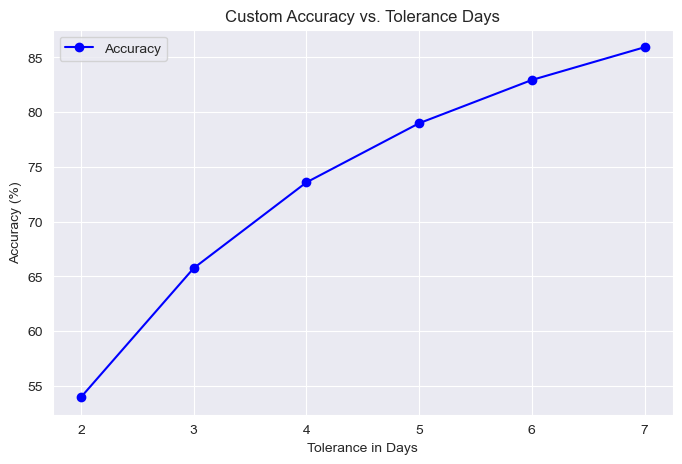

In [58]:
# Plot accuracy vs. tolerance days
plt.figure(figsize=(8, 5))
plt.plot(tolerance_values, accuracy, marker='o', linestyle='-', color='b', label='Accuracy')

# Labels and Title
plt.xlabel("Tolerance in Days")
plt.ylabel("Accuracy (%)")
plt.title("Custom Accuracy vs. Tolerance Days")
plt.xticks(tolerance_values)  # Ensure correct tick labels
plt.grid(True)
plt.legend()

# Show the plot
plt.show()
